# A crypto data lakehouse with Polars and DuckDB

**Objective:** work with a dataset that is too big to be comfortable in pandas: 7 million 1-minute candles of 5 cryptocurrencies (2024 to September 2026). The data is stored as parquet partitioned by symbol, year and month (`ingest.py`), and we query it with **Polars** (lazy) and **DuckDB** (SQL) directly on the files.

1. Data quality checks (missing minutes, duplicates, impossible prices)
2. Benchmark: the same aggregation in pandas, Polars and DuckDB
3. Analysis: realised volatility, intraday pattern, weekends, Bitcoin realised volatility against the implied volatility of Deribit (DVOL)

**Data:** Binance public data (data.binance.vision), spot klines of 1 minute for BTC, ETH, SOL, BNB and XRP against USDT. DVOL from the Deribit public API.

Libraries of the project: `polars`, `duckdb`, `pandas`, `numpy`, `matplotlib` and `seaborn`.

## Part 1. Libraries and the lake

In [1]:
import os
import time
import numpy as np
import pandas as pd
import polars as pl
import duckdb
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
os.makedirs("figures", exist_ok=True)

lago = "lake/klines/**/*.parquet"
klines = pl.scan_parquet(lago, hive_partitioning=True)       # lazy: nothing is read yet
print(klines.collect_schema())
print("Rows:", klines.select(pl.len()).collect().item())

Schema({'ts': Datetime(time_unit='us', time_zone=None), 'open': Float64, 'high': Float64, 'low': Float64, 'close': Float64, 'volume': Float64, 'quote_volume': Float64, 'trades': Int64, 'taker_buy_volume': Float64, 'symbol': String, 'year': Int64, 'month': Int64})
Rows: 7228800


## Part 2. Data quality

- Every symbol should have one candle per minute: we count the missing minutes
- No duplicated timestamps
- High >= max(open, close) and low <= min(open, close), prices and volumes positive

In [2]:
calidad = (klines.group_by("symbol")
           .agg(pl.len().alias("rows"), pl.col("ts").min().alias("first"), pl.col("ts").max().alias("last"),
                pl.col("ts").n_unique().alias("unique_ts"),
                ((pl.col("high") < pl.max_horizontal("open", "close")) | (pl.col("low") > pl.min_horizontal("open", "close"))).sum().alias("bad_high_low"),
                (pl.col("close") <= 0).sum().alias("non_positive_price"))
           .with_columns(((pl.col("last") - pl.col("first")).dt.total_minutes() + 1).alias("expected_minutes"))
           .with_columns((pl.col("expected_minutes") - pl.col("unique_ts")).alias("missing_minutes"),
                         (pl.col("rows") - pl.col("unique_ts")).alias("duplicates"))
           .sort("symbol").collect())
calidad

symbol,rows,first,last,unique_ts,bad_high_low,non_positive_price,expected_minutes,missing_minutes,duplicates
str,u32,datetime[μs],datetime[μs],u32,u32,u32,i64,i64,u32
"""BNBUSDT""",1445760,2024-01-01 00:00:00,2026-09-30 23:59:00,1445760,0,0,1445760,0,0
"""BTCUSDT""",1445760,2024-01-01 00:00:00,2026-09-30 23:59:00,1445760,0,0,1445760,0,0
"""ETHUSDT""",1445760,2024-01-01 00:00:00,2026-09-30 23:59:00,1445760,0,0,1445760,0,0
"""SOLUSDT""",1445760,2024-01-01 00:00:00,2026-09-30 23:59:00,1445760,0,0,1445760,0,0
"""XRPUSDT""",1445760,2024-01-01 00:00:00,2026-09-30 23:59:00,1445760,0,0,1445760,0,0


In [3]:
# minutes without any trade
klines.group_by("symbol").agg((pl.col("trades") == 0).sum().alias("minutes_without_trades")).sort("symbol").collect()

symbol,minutes_without_trades
str,u32
"""BNBUSDT""",0
"""BTCUSDT""",0
"""ETHUSDT""",0
"""SOLUSDT""",0
"""XRPUSDT""",0


The lake is complete: no missing minutes, no duplicates and no impossible prices in the 7.2 million rows. The checks are still worth having in the pipeline, because the format of the source changes (in January 2025 Binance moved the timestamps from milliseconds to microseconds, and `ingest.py` detects it).

## Part 3. Benchmark: pandas vs Polars vs DuckDB

The same query in the three engines: daily realised volatility of each symbol (sum of the squared 1-minute log returns), on the 7 million rows.

In [4]:
tiempos = {}

t0 = time.perf_counter()
pdf = pd.read_parquet("lake/klines")
pdf = pdf.sort_values(["symbol", "ts"])
pdf["r"] = np.log(pdf["close"]).groupby(pdf["symbol"]).diff()
pdf["day"] = pdf["ts"].dt.floor("D")
rv_pandas = pdf.groupby(["symbol", "day"])["r"].apply(lambda r: np.sqrt((r ** 2).sum()))
tiempos["pandas"] = time.perf_counter() - t0
del pdf

t0 = time.perf_counter()
rv_polars = (klines.sort(["symbol", "ts"])
             .with_columns(pl.col("close").log().diff().over("symbol").alias("r"))
             .group_by("symbol", pl.col("ts").dt.truncate("1d").alias("day"))
             .agg((pl.col("r") ** 2).sum().sqrt().alias("rv"))
             .collect())
tiempos["polars (lazy)"] = time.perf_counter() - t0

t0 = time.perf_counter()
rv_duck = duckdb.sql(f"""
    with r as (
        select symbol, ts, ln(close) - lag(ln(close)) over (partition by symbol order by ts) as r
        from read_parquet('{lago}', hive_partitioning = true)
    )
    select symbol, date_trunc('day', ts) as day, sqrt(sum(r * r)) as rv
    from r group by 1, 2
""").df()
tiempos["duckdb (SQL)"] = time.perf_counter() - t0

print("Same result:", np.isclose(rv_polars["rv"].sum(), rv_duck["rv"].sum()), np.isclose(rv_pandas.sum(), rv_duck["rv"].sum()))
pd.Series(tiempos, name="seconds").round(2)

C:\Users\lezqu\AppData\Local\Temp\ipykernel_25536\3352566815.py:6: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  pdf["r"] = np.log(pdf["close"]).groupby(pdf["symbol"]).diff()


C:\Users\lezqu\AppData\Local\Temp\ipykernel_25536\3352566815.py:8: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  rv_pandas = pdf.groupby(["symbol", "day"])["r"].apply(lambda r: np.sqrt((r ** 2).sum()))


Same result: True True


pandas           2.89
polars (lazy)    0.88
duckdb (SQL)     1.14
Name: seconds, dtype: float64

## Part 4. Realised volatility of the 5 coins

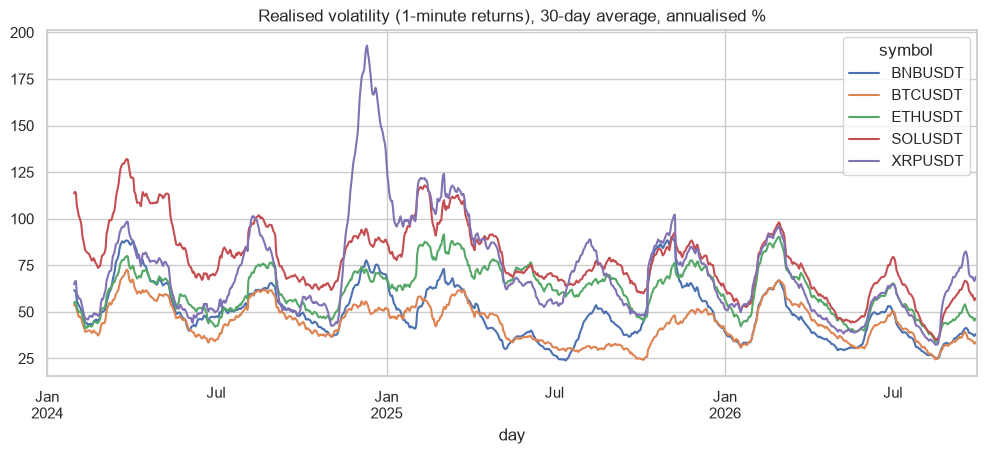

symbol
BNBUSDT    44.1
BTCUSDT    40.9
ETHUSDT    55.8
SOLUSDT    71.5
XRPUSDT    61.0
dtype: float64

In [5]:
rv = rv_polars.to_pandas()
rv["rv_annual"] = rv["rv"] * np.sqrt(365) * 100
piv = rv.pivot(index="day", columns="symbol", values="rv_annual").sort_index()
piv.rolling(30).mean().plot(figsize=(12, 4.5))
plt.title("Realised volatility (1-minute returns), 30-day average, annualised %")
plt.savefig("figures/realised_vol.png", bbox_inches="tight")
plt.show()
piv.median().round(1)

## Part 5. When does crypto move? Intraday pattern and weekends

With SQL in DuckDB: average absolute 1-minute return and volume by hour of the day (UTC) and by day of the week, for Bitcoin.

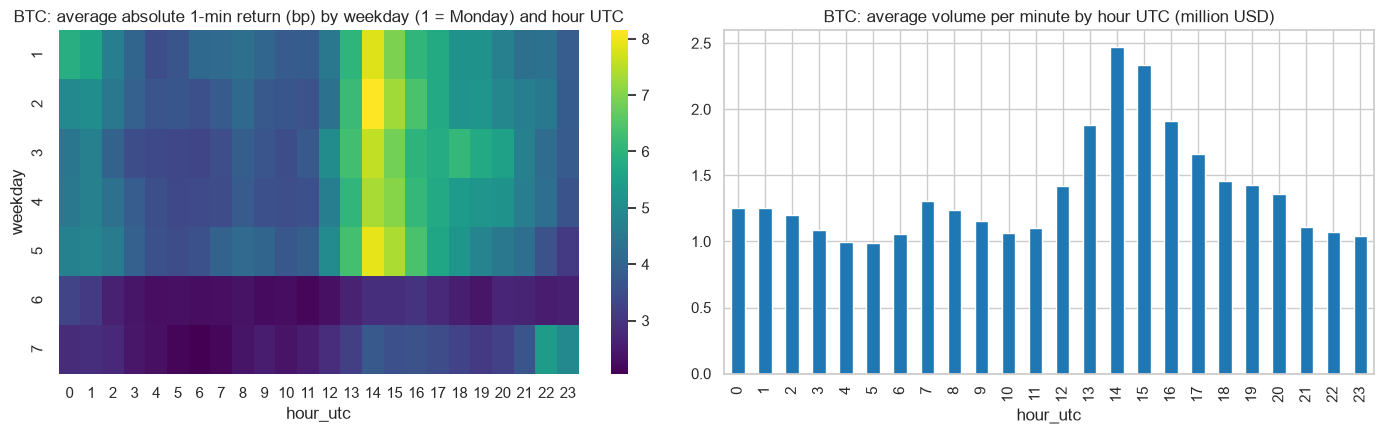

Most volatile hour UTC: 14 | quietest: 5
Weekend vs weekdays (avg abs return): 0.59


In [6]:
patron = duckdb.sql(f"""
    with b as (
        select ts, quote_volume, abs(ln(close) - lag(ln(close)) over (order by ts)) as abs_r
        from read_parquet('{lago}', hive_partitioning = true)
        where symbol = 'BTCUSDT'
    )
    select hour(ts) as hour_utc, isodow(ts) as weekday, avg(abs_r) * 1e4 as avg_abs_return_bp, avg(quote_volume) / 1e6 as avg_volume_musd
    from b group by 1, 2 order by 1, 2
""").df()

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
sns.heatmap(patron.pivot(index="weekday", columns="hour_utc", values="avg_abs_return_bp"), cmap="viridis", ax=axes[0])
axes[0].set_title("BTC: average absolute 1-min return (bp) by weekday (1 = Monday) and hour UTC")
por_hora = patron.groupby("hour_utc")[["avg_abs_return_bp", "avg_volume_musd"]].mean()
por_hora["avg_volume_musd"].plot.bar(ax=axes[1], color="tab:blue")
axes[1].set_title("BTC: average volume per minute by hour UTC (million USD)")
plt.tight_layout()
plt.savefig("figures/intraday_pattern.png", bbox_inches="tight")
plt.show()
print("Most volatile hour UTC:", por_hora["avg_abs_return_bp"].idxmax(), "| quietest:", por_hora["avg_abs_return_bp"].idxmin())
semana = patron.groupby("weekday")["avg_abs_return_bp"].mean()
print("Weekend vs weekdays (avg abs return):", round(semana.loc[[6, 7]].mean() / semana.loc[1:5].mean(), 2))

The busiest hours are the US market open (around 13:30-15:00 UTC) and the moments of US macro data; weekends are much calmer, because traditional investors and the market makers that link crypto with other markets are not active.

## Part 6. Bitcoin: realised vs implied volatility (Deribit DVOL)

DVOL is the 30-day implied volatility of Bitcoin options. We compare it with the realised volatility of the **next** 30 days, like the VIX vs S&P 500 comparison.

Days: 974 | average premium: 2.7 vol points | share of days with DVOL above: 0.664


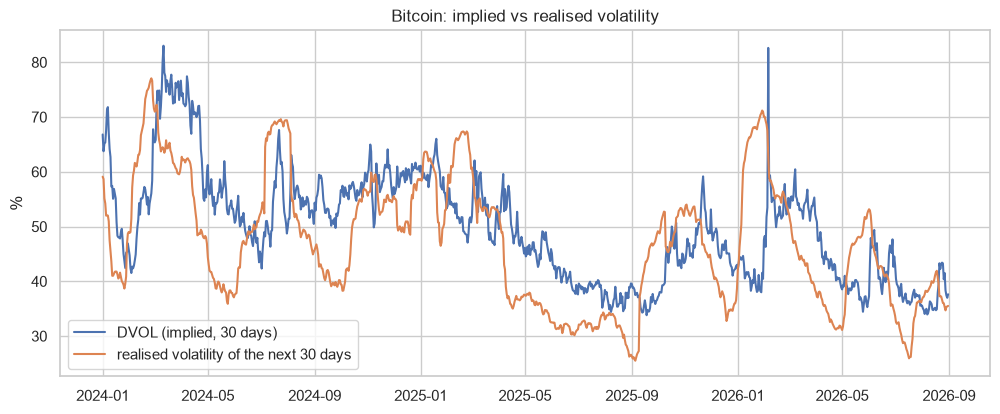

In [7]:
dvol = pd.read_parquet("data/deribit_dvol_1h.parquet")
dvol = dvol.set_index("ts")["dvol"].resample("D").last()
btc = piv["BTCUSDT"]
btc.index = pd.to_datetime(btc.index, utc=True)
futura = (btc ** 2).rolling(30).mean().pow(0.5).shift(-30)       # realised vol of the next 30 days
vrp = pd.DataFrame({"dvol": dvol, "realised_next_30d": futura}).dropna()
vrp["premium"] = vrp["dvol"] - vrp["realised_next_30d"]
print("Days:", len(vrp), "| average premium:", round(vrp["premium"].mean(), 1), "vol points | share of days with DVOL above:", round((vrp["premium"] > 0).mean(), 3))

plt.figure(figsize=(12, 4.5))
plt.plot(vrp.index, vrp["dvol"], label="DVOL (implied, 30 days)")
plt.plot(vrp.index, vrp["realised_next_30d"], label="realised volatility of the next 30 days")
plt.title("Bitcoin: implied vs realised volatility")
plt.ylabel("%")
plt.legend()
plt.savefig("figures/btc_dvol_vs_realised.png", bbox_inches="tight")
plt.show()

## Conclusions

- Polars (lazy) and DuckDB do the same aggregation on 7.2 million rows around 3 times faster than pandas (2.3 and 2.6 seconds against 7.1), and without loading everything in memory first. The three engines give the same result.
- Realised volatility (median, annualised): BTC 41%, BNB 44%, ETH 56%, XRP 61%, SOL 72%.
- Bitcoin moves the most at 14:00 UTC (US market open and macro data) and the least at 05:00 UTC; on weekends the average absolute return is 41% lower than on weekdays.
- Like the VIX for the S&P 500, the implied volatility of Bitcoin (DVOL) is above the realised volatility of the next 30 days in 66% of the days, by 2.7 points on average: buying Bitcoin options has been expensive on average.